# MLP in PyTorch (TP05)
A dense network on the paintings: first the 1-hidden-layer sigmoid network of TP05 Part A, then a tuned ReLU network (TP05 Exercise 20).

In [27]:
import os
os.chdir("..")                      # run from the repo root, where data/ and splits/ are

import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix

from museum_guide.data import load_images, get_dataloaders

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS_A = 10                               # epochs for the Part A network
BATCH_SIZE = 128
LR = 0.2                                    # SGD learning rate of Part A
CLASSES = ["Baroque", "Cubism", "Impressionism", "Pop_Art", "Ukiyo_e"]
print("device:", device)

device: cpu


In [28]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history


def show_images(images, titles, n=10):
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 1.9))
    for ax, img, title in zip(axes, images[:n], titles[:n]):
        ax.imshow(img.permute(1, 2, 0).cpu())          # colour image: (3, H, W) -> (H, W, 3)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.show()

In [29]:
train_loader, val_loader, test_loader = get_dataloaders("mlp", batch_size=BATCH_SIZE)
X, y, meta = load_images()
split = pd.read_csv("splits/split.csv")
X_test_raw = X[torch.tensor((split["split"] == "test").values)]     # test images in [0, 1], to look at them
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))

FileNotFoundError: [Errno 2] No such file or directory: 'data/wikiart_style5'

In [ ]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 64 * 64, 128),
    nn.Sigmoid(),
    nn.Linear(128, 5)
).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("parameters:", n_params)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=5, bias=True)
)
parameters: 1573637


In [ ]:
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
epochs = EPOCHS_A
history_a = fit(model, train_loader, val_loader, loss_fn, optimizer, epochs)

epoch  1 | train loss 1.5574 | val loss 1.5281 | val acc 0.316
epoch  2 | train loss 1.4520 | val loss 1.4868 | val acc 0.384
epoch  3 | train loss 1.4098 | val loss 1.5167 | val acc 0.348
epoch  4 | train loss 1.3644 | val loss 1.4888 | val acc 0.372
epoch  5 | train loss 1.2920 | val loss 1.5001 | val acc 0.420
epoch  6 | train loss 1.3180 | val loss 1.5260 | val acc 0.348
epoch  7 | train loss 1.2221 | val loss 1.5418 | val acc 0.364
epoch  8 | train loss 1.1510 | val loss 1.5220 | val acc 0.400
epoch  9 | train loss 1.1335 | val loss 1.5451 | val acc 0.396
epoch 10 | train loss 1.1292 | val loss 1.9324 | val acc 0.328


In [ ]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"test accuracy of the Part A network: {test_acc:.3f}")

test accuracy of the Part A network: 0.284


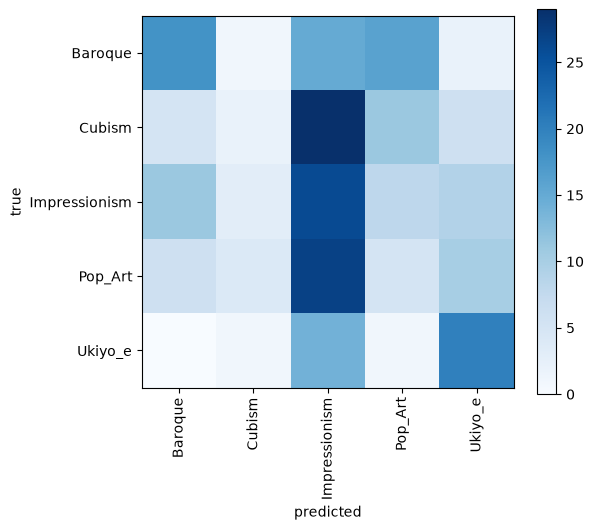

most frequent mistake: Cubism predicted as Impressionism (29 times)


In [ ]:
preds = []
true_labels = []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        preds.append(logits.argmax(dim=1).cpu())
        true_labels.append(yb)
preds = torch.cat(preds)
true_labels = torch.cat(true_labels)
cm = confusion_matrix(true_labels, preds, labels=range(5))
off = cm.copy()
np.fill_diagonal(off, 0)
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(5), CLASSES, rotation=90); plt.yticks(range(5), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

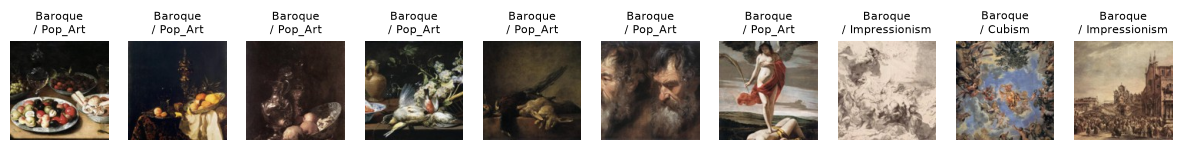

In [ ]:
wrong = (preds != true_labels).nonzero(as_tuple=True)[0]
pred = preds[wrong]
show_images(X_test_raw[wrong], [f"{CLASSES[true_labels[i]]}\n/ {CLASSES[preds[i]]}" for i in wrong[:10]])

In [ ]:
def init_weights(model, kind):
    for m in model:
        if isinstance(m, nn.Linear):
            if kind == "zeros":
                nn.init.zeros_(m.weight)
            elif kind == "small":
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
            elif kind == "large":
                nn.init.normal_(m.weight, mean=0.0, std=1.0)
            elif kind == "xavier":
                nn.init.xavier_normal_(m.weight)
            elif kind == "he":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            nn.init.zeros_(m.bias)
    return model

In [ ]:
# Commented out to not define variables twice. This cell was converted to the cell below
# epochs_gf = 12
# torch.manual_seed(0)
# model_gf = nn.Sequential(
#     nn.Flatten(),
#     nn.Linear(3 * 64 * 64, 256), nn.ReLU(),
#     nn.Linear(256, 128), nn.ReLU(),
#     nn.Linear(128, 64), nn.ReLU(),
#     nn.Linear(64, 5)
# ).to(device)
# model_gf = init_weights(model_gf, "he")
# optimizer = torch.optim.Adam(model_gf.parameters(), lr=1e-3)
# history_gf = fit(model_gf, train_loader, val_loader, loss_fn, optimizer, epochs_gf)
# test_loss_gf, test_acc_gf = evaluate(model_gf, test_loader, loss_fn)
# print(f"test accuracy: {test_acc_gf:.3f} (Part A network: {test_acc:.3f}, baseline: 0.372)")

In [ ]:
# Train the tuned ReLU network, keeping the best epoch (lowest val_loss)
import copy
from museum_guide.mlp import make_tuned_mlp

def fit_with_best(model, train_loader, val_loader, loss_fn, optimizer,
                  n_epochs, device=None):
    """Train and return (history, best_epoch); restore weights of the epoch with lowest val_loss.

    Uses the notebook-local train_one_epoch / evaluate (4-arg and 3-arg versions),
    so it does not clash with the module-level versions in museum_guide.train.
    """
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_val, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(n_epochs):
        tr = train_one_epoch(model, train_loader, loss_fn, optimizer) # 4 args (TP04 Ex 24)
        vl, va = evaluate(model, val_loader, loss_fn) # 3 args (TP04 Ex 20)
        history["train_loss"].append(tr)
        history["val_loss"].append(vl)
        history["val_acc"].append(va)
        if vl < best_val:
            best_val = vl
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict()) # TP06 Ex 10
    model.load_state_dict(best_state)
    return history, best_epoch

torch.manual_seed(0)
model_gf = make_tuned_mlp().to(device) # He init already applied inside make_tuned_mlp (TP05 Ex 17)
optimizer = torch.optim.Adam(model_gf.parameters(), lr=1e-3)
history_gf, best_epoch = fit_with_best(
    model_gf, train_loader, val_loader, loss_fn, optimizer,
    n_epochs=12, device=device,
)
test_loss_gf, test_acc_gf = evaluate(model_gf, test_loader, loss_fn) # 3-arg version
print(f"test acc = {test_acc_gf:.3f} | best epoch = {best_epoch}")

test acc = 0.356 | best epoch = 8


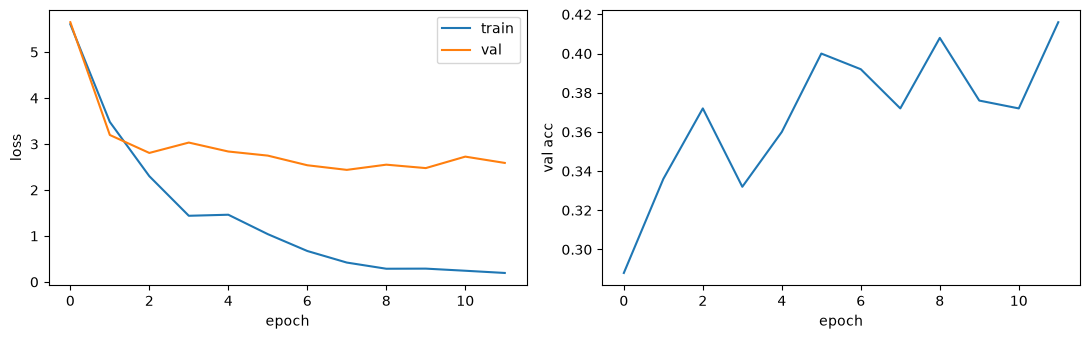

In [ ]:
# Save learning curves -> results/figures/mlp_curves.png
# TP reference: TP04 Exercise 21 (the two-panel loss / accuracy plot helper)
from pathlib import Path
Path("results/figures").mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history_gf["train_loss"], label="train")
ax[0].plot(history_gf["val_loss"], label="val")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].plot(history_gf["val_acc"])
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val acc")
plt.tight_layout()
plt.savefig("results/figures/mlp_curves.png", dpi=120)
plt.show()

In [ ]:
# Save JSON metrics -> results/metrics/ (history + test accuracy / baseline / best epoch)
# TP reference: same artefact-saving convention used across TP04–TP07 notebooks (save what you measure: losses, accuracy, extra metadata)
import json
from pathlib import Path
Path("results/metrics").mkdir(parents=True, exist_ok=True)

json.dump(history_gf,
          open("results/metrics/mlp_history.json", "w"), indent=2)
json.dump({"accuracy": test_acc_gf,
           "baseline_part_a": test_acc,      # Part A accuracy from cell 9c31ae30 (TP05 Part A)
           "best_epoch": best_epoch},
          open("results/metrics/mlp_test.json", "w"), indent=2)

In [ ]:
# Save model checkpoint -> checkpoints/mlp_best.pt (best-epoch weights)
# TP reference: TP04 Exercise 22 (torch.save of model.state_dict(), reload with load_state_dict)
from pathlib import Path
Path("checkpoints").mkdir(parents=True, exist_ok=True)
torch.save(model_gf.state_dict(), "checkpoints/mlp_best.pt")

## Conclusion (updated Oct 24, Luli)
- Part A network (1 hidden sigmoid layer, SGD lr 0.2): test accuracy 0.284, below the 0.372 baseline. 
  val_acc jumps between 0.29 and 0.42 epoch to epoch: lr = 0.2 is too large for plain SGD, and with only 
  ~250 validation images each epoch's accuracy carries ±3–6 points of noise.

- Tuned ReLU network (3 hidden layers 256-128-64, He init, Adam lr 1e-3, best-val_loss checkpoint): 
  test accuracy 0.356. That is +7 points over Part A, but still **~2 points below the 0.372 
  baseline** and well inside the noise band of the 250-image test set. It is not a real win over the 
  baseline.

- fit_with_best kept epoch 8 (lowest val_loss = 2.437), but val_loss and val_acc do not peak together 
  here: val_acc is highest at epoch 11 (0.416) when val_loss is 2.588. Selecting on val_loss therefore 
  missed the more accurate checkpoint — this is why keeping the "best loss" epoch gave a lower test 
  accuracy than keeping the last epoch (0.388 in the pre-B1 run).

- The model clearly overfits: train loss falls from 5.60 to 0.19, while val_loss stays around 2.4–2.7 
  from epoch 8 onwards. 3.2 M parameters for 1000 training images is ~3200 parameters per image.

- Most frequent mistake: Cubism predicted as Impressionism (~30 times). A dense network sees pixels at 
  fixed positions, not shapes or brush strokes, so it cannot separate these two styles.

- Takeaway: this MLP tops out around the baseline. The honest fixes are (a) regularisation — Task 2: 
  dropout, weight decay, early stopping — and (b), above all, a convolutional architecture that exploits 
  image locality and translation invariance — Task 3: ResNet.

- Chance level: 0.20.